## 1. Import Libraries

In this section, we import all the Python packages needed for the project.  
These include:
- `pandas` for data manipulation  
- `numpy` for numerical operations  
- `glob` for collecting multiple CSV files  
- `statsmodels` for logistic regression modeling


In [4]:
from google.colab import drive
import pandas as pd
import glob
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor



## 2. Load and Combine ATP Match Data

In this section, we connect to Google Drive, locate all ATP match files from the
`tennis_atp` dataset, and combine them into a single DataFrame.

The files we load are named `atp_matches_*.csv`, which correspond to ATP Tour-level
singles matches for each year. Using `glob`, we gather all matching files and
concatenate them into one unified dataset containing all matches across all seasons.

In [5]:
path = "/content/drive/MyDrive/Math 50 Final Project/tennis_atp-master/"
files = sorted(glob.glob(path + "atp_matches_*.csv"))

#Should be 57
print("Number of files found:", len(files))

# Combine files into one dataset
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

#Should be 194996
print("Number of data points: "+ str(df.shape[0]))

Number of files found: 56
Number of data points: 191920


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Construct Player-Level Dataset (Stacked Winner and Loser Rows)

The ATP match data contains one row per match, with statistics for both the winner and
the loser included together. To run a logistic regression predicting whether a player
wins a match, we need one row per player per match.

We create:

- A **winner row** with `win = 1`  
- A **loser row** with `win = 0`  

For each row, we compute first-serve percentage using:

$$\text{First Serve %} = \frac{\text{1stIn}}{\text{SvPts}}$$

As well as computing:
- Height (cm)
- Age
- Double Faults




This dataset structure allows us to model how a player's first-serve accuracy, height, age, and double faults relate to their probability of winning.

In [7]:
# Winner rows
w = pd.DataFrame({
    'win': 1,
    'surface': df['surface'],

    # Serve stats
    'first_serve_pct': df['w_1stIn'] / df['w_svpt'],
    'first_serve_points_won': df['w_1stWon'] / df['w_1stIn'],
    'aces': df['w_ace'],
    'double_faults': df['w_df'],

    # Return stat: winner returning opponent’s 1st serve
    'return_1st_points_won': (df['l_1stIn'] - df['l_1stWon']) / df['l_1stIn'],

    # Player characteristics
    'height': df['winner_ht'],
    'age': df['winner_age']
})

# Loser rows
l = pd.DataFrame({
    'win': 0,
    'surface': df['surface'],

    # Serve stats
    'first_serve_pct': df['l_1stIn'] / df['l_svpt'],
    'first_serve_points_won': df['l_1stWon'] / df['l_1stIn'],
    'aces': df['l_ace'],
    'double_faults': df['l_df'],

    # Return stat: loser returning opponent’s 1st serve
    'return_1st_points_won': (df['w_1stIn'] - df['w_1stWon']) / df['w_1stIn'],

    # Player characteristics
    'height': df['loser_ht'],
    'age': df['loser_age']
})

# Combine
combined = pd.concat([w, l], ignore_index=True)

# Clean dataset
combined = combined.replace([float('inf'), -float('inf')], pd.NA)
combined = combined.dropna()

print("Combined shape:", combined.shape)
print(combined.head())

Combined shape: (188950, 9)
       win surface  first_serve_pct  first_serve_points_won  aces  \
86621    1    Hard         0.572917                0.709091   6.0   
86622    1    Hard         0.554455                0.803571  19.0   
86623    1    Hard         0.574074                0.774194   6.0   
86624    1    Hard         0.666667                0.750000   2.0   
86625    1    Hard         0.555556                0.825000   4.0   

       double_faults  return_1st_points_won  height   age  
86621            2.0               0.290323   193.0  20.7  
86622            4.0               0.146341   198.0  27.4  
86623            1.0               0.405405   190.0  24.8  
86624            0.0               0.333333   178.0  19.7  
86625            2.0               0.317073   185.0  24.4  


## 6. Summary Statistics by Outcome

Before fitting the logistic regression model, we compare descriptive statistics
for the entire dataset and separately for match winners and losers. This helps
identify baseline differences between the two groups and provides context for
our modeling choices.

In particular, if winners tend to have higher first-serve percentage or fewer
double faults on average, this would support our predictors and align with the
findings of Bieniek & Kwater (2015), who report that serve effectiveness is
positively associated with match success.

In [8]:
# Overall summary
print("=== Overall Summary ===")
display(combined.describe())

# Winners only
print("\n=== Winners Summary ===")
winners = combined[combined['win'] == 1]
display(winners.describe())

# Losers only
print("\n=== Losers Summary ===")
losers = combined[combined['win'] == 0]
display(losers.describe())

=== Overall Summary ===


,win,first_serve_pct,first_serve_points_won,aces,double_faults,return_1st_points_won,height,age
count,188950.000000,188950.000000,188950.000000,188950.000000,188950.000000,188950.000000,188950.000000,188950.000000
mean,0.501889,0.601126,0.711173,5.702990,3.100820,0.289576,185.573030,25.983085
std,0.499998,0.086715,0.105343,5.090642,2.519376,0.105609,6.715547,3.837524
min,0.000000,0.125000,0.000000,0.000000,0.000000,0.000000,15.000000,14.900000
25%,0.000000,0.543478,0.644068,2.000000,1.000000,0.216667,180.000000,23.100000
50%,1.000000,0.600000,0.714286,4.000000,3.000000,0.285714,185.000000,25.700000
75%,1.000000,0.657895,0.783784,8.000000,4.000000,0.357143,190.000000,28.500000
max,1.000000,1.000000,1.000000,113.000000,26.000000,1.000000,211.000000,44.000000



=== Winners Summary ===


,win,first_serve_pct,first_serve_points_won,aces,double_faults,return_1st_points_won,height,age
count,94832.0,94832.000000,94832.000000,94832.000000,94832.000000,94832.000000,94832.000000,94832.000000
mean,1.0,0.610496,0.764711,6.533248,2.728151,0.343332,185.855987,25.900187
std,0.0,0.085854,0.083255,5.333737,2.361499,0.097750,6.719501,3.794651
min,1.0,0.125000,0.000000,0.000000,0.000000,0.000000,163.000000,14.900000
25%,1.0,0.553191,0.707692,3.000000,1.000000,0.276596,181.000000,23.100000
50%,1.0,0.610169,0.764706,5.000000,2.000000,0.339623,185.000000,25.600000
75%,1.0,0.666667,0.821429,9.000000,4.000000,0.404255,190.000000,28.400000
max,1.0,1.000000,1.000000,113.000000,26.000000,1.000000,211.000000,42.700000



=== Losers Summary ===


,win,first_serve_pct,first_serve_points_won,aces,double_faults,return_1st_points_won,height,age
count,94118.0,94118.000000,94118.000000,94118.000000,94118.000000,94118.000000,94118.000000,94118.000000
mean,0.0,0.591684,0.657229,4.866434,3.476317,0.235411,185.287926,26.066612
std,0.0,0.086554,0.097449,4.686915,2.615876,0.083176,6.699520,3.878472
min,0.0,0.125000,0.000000,0.000000,0.000000,0.000000,15.000000,15.000000
25%,0.0,0.534884,0.596198,2.000000,2.000000,0.178571,180.000000,23.200000
50%,0.0,0.591837,0.660714,4.000000,3.000000,0.235294,185.000000,25.800000
75%,0.0,0.648649,0.723404,7.000000,5.000000,0.292308,190.000000,28.700000
max,0.0,1.000000,1.000000,103.000000,26.000000,1.000000,211.000000,44.000000


## 7. Logistic Regression Model

We now fit a logistic regression where the response variable is `win` (1 for a match
win, 0 for a loss). The predictors are:

- First-serve percentage
- Height (cm)
- Age
- Double faults

This model allows us to quantify how each factor changes the odds that a player
wins a match, extending the correlational findings of Bieniek & Kwater (2015)
using match-level data and a probability model.

In [9]:
# predictors (serve + demographics only)
X = combined[['first_serve_pct',
              'first_serve_points_won',
              'aces',
              'height',
              'age',
              'double_faults']]

# If you want surface later, uncomment:
# surface_dummies = pd.get_dummies(combined['surface'], drop_first=True)
# X = pd.concat([X, surface_dummies], axis=1)

# add intercept
X = sm.add_constant(X)

# response
y = combined['win']

# logistic regression
model = sm.Logit(y, X).fit()

model.summary()

Optimization terminated successfully.
         Current function value: 0.506228
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                    win   No. Observations:               188950
Model:                          Logit   Df Residuals:                   188943
Method:                           MLE   Df Model:                            6
Date:                Wed, 15 Apr 2026   Pseudo R-squ.:                  0.2697
Time:                        14:28:02   Log-Likelihood:                -95652.
converged:                       True   LL-Null:                   -1.3097e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -6.9648      0.182    -38.210      0.000      -7.322      -6.608
first_serve_pct            4.4626      0.072     62.326      0.000       4.322       4.603
first_serve_points_won    16.2719      0.086    189.786      0.000      16.104      16.440
aces                      -0.0273      0.001    -20.379      0.000      -0.030      -0.025
height                    -0.0320      0.001    -34.755      0.000      -0.034      -0.030
age                       -0.0322      0.001    -21.889      0.000      -0.035      -0.029
double_faults             -0.1183      0.002    -48.733      0.000      -0.123      -0.114
==========================================================================================
"""

## 8. Multicollinearity Diagnosis (Variance Inflation Factors)

To check whether our predictors are excessively correlated with each other, we compute
Variance Inflation Factors (VIFs). A VIF of:

- 1–2 → very low collinearity  
- 2–5 → moderate, acceptable  
- 5–10 → high, potentially concerning  
- >10 → severe multicollinearity  

This helps confirm whether predictors like height, age, first-serve percentage, and
double faults contain redundant information.

In [10]:
# full predictor matrix for VIF
X_vif = combined[['first_serve_pct',
                  'first_serve_points_won',
                  'return_1st_points_won',
                  'aces',
                  'height',
                  'age',
                  'double_faults']]

# add constant term
X_vif = sm.add_constant(X_vif)

# compute VIF for each predictor
vif_df = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
})

vif_df

,Variable,VIF
0,const,1035.941257
1,first_serve_pct,1.113714
2,first_serve_points_won,1.356242
3,return_1st_points_won,1.071090
4,aces,1.545616
5,height,1.199048
6,age,1.007448
7,double_faults,1.178794


In [11]:
import statsmodels.api as sm

# restrict to standard surfaces
combined_surf = combined[combined['surface'].isin(['Hard', 'Clay', 'Grass'])]

surface_models = {}

for court in ['Hard', 'Clay', 'Grass']:
    print(f"\n\n======================== {court.upper()} ========================\n")

    df_s = combined_surf[combined_surf['surface'] == court]

    # predictors (NO return stats)
    X_s = df_s[['first_serve_pct',
                'first_serve_points_won',
                'aces',
                'height',
                'age',
                'double_faults']]

    # add constant
    X_s = sm.add_constant(X_s)

    # response
    y_s = df_s['win']

    # fit model
    model_s = sm.Logit(y_s, X_s).fit(disp=False)
    surface_models[court] = model_s

    print(model_s.summary())



======================== HARD ========================

                           Logit Regression Results                           
Dep. Variable:                    win   No. Observations:                95971
Model:                          Logit   Df Residuals:                    95964
Method:                           MLE   Df Model:                            6
Date:                Wed, 15 Apr 2026   Pseudo R-squ.:                  0.2742
Time:                        14:28:03   Log-Likelihood:                -48279.
converged:                       True   LL-Null:                       -66521.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -7.1344      0.253    -28.171      0.000      -7.631      -6.638
first_serve_pct            4.4079    

Height Coefficient Comparison:
            Model  Height Coefficient
0      Serve-Only           -0.032036
1  Serve + Return           -0.028418


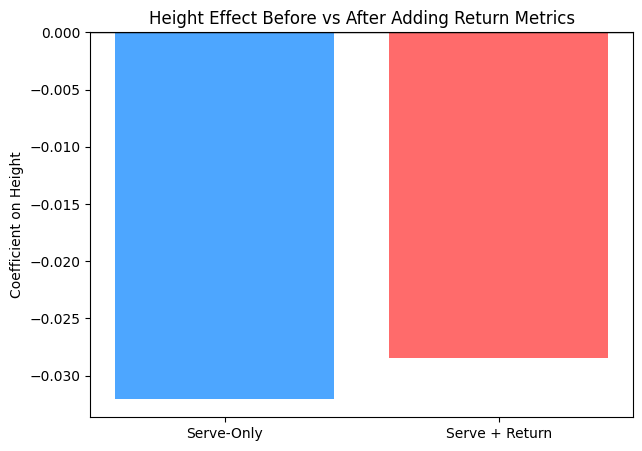

In [12]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------
# MODEL A: Serve-Only Predictors
# ------------------------------

X_A = combined[['first_serve_pct',
                'first_serve_points_won',
                'aces',
                'double_faults',
                'age',
                'height']]

X_A = sm.add_constant(X_A)
y = combined['win']

model_A = sm.Logit(y, X_A).fit(disp=False)
coef_A = model_A.params['height']


# ------------------------------------------
# MODEL B: Serve + Return (Full Bieniek Model)
# ------------------------------------------

X_B = combined[['first_serve_pct',
                'first_serve_points_won',
                'return_1st_points_won',
                'aces',
                'double_faults',
                'age',
                'height']]

X_B = sm.add_constant(X_B)

model_B = sm.Logit(y, X_B).fit(disp=False)
coef_B = model_B.params['height']


# ------------------------------
# Show comparison side-by-side
# ------------------------------
comparison = pd.DataFrame({
    'Model': ['Serve-Only', 'Serve + Return'],
    'Height Coefficient': [coef_A, coef_B]
})

print("Height Coefficient Comparison:")
print(comparison)


# -----------------------------
#            PLOT
# -----------------------------
plt.figure(figsize=(7,5))
plt.bar(['Serve-Only', 'Serve + Return'],
        [coef_A, coef_B],
        color=['#4DA6FF','#FF6B6B'])
plt.axhline(0, color='black', linewidth=1)
plt.title("Height Effect Before vs After Adding Return Metrics")
plt.ylabel("Coefficient on Height")
plt.show()

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Helper logistic function
def logistic(z):
    return 1 / (1 + np.exp(-z))

# Variables to plot
variables = ["first_serve_points_won", "return_1st_points_won", "height", "double_faults"]

# Ranges for each variable
ranges = {
    "first_serve_points_won": np.linspace(0.40, 0.90, 300),
    "return_1st_points_won": np.linspace(0.10, 0.55, 300),
    "height": np.linspace(170, 205, 300),
    "double_faults": np.linspace(0, 10, 300)
}

# Only numeric predictors — no surface
numeric_cols = ['first_serve_pct',
                'first_serve_points_won',
                'return_1st_points_won',
                'aces',
                'height',
                'age',
                'double_faults']

median_vals = combined_surf[numeric_cols].median()

# Generate plots
for var in variables:
    plt.figure(figsize=(8, 6))

    for court in ["Hard", "Clay", "Grass"]:
        model = surface_models[court]
        betas = model.params

        x_vals = ranges[var]
        preds = []

        for x in x_vals:
            row = median_vals.copy()
            row[var] = x

            # Construct X_row in proper order
            X_row = [1]  # intercept
            for col in ["first_serve_pct",
                        "first_serve_points_won",
                        "return_1st_points_won",
                        "aces",
                        "height",
                        "age",
                        "double_faults"]:
                X_row.append(row[col])

            z = np.dot(betas.values, X_row)
            preds.append(logistic(z))

        plt.plot(x_vals, preds, label=court)

    plt.xlabel(var.replace('_',' ').title())
    plt.ylabel("Predicted Win Probability")
    plt.title(f"Win Probability vs {var.replace('_',' ').title()} by Surface")
    plt.legend()
    plt.grid(True)
    plt.show()

ValueError: shapes (7,) and (8,) not aligned: 7 (dim 0) != 8 (dim 0)

<Figure size 800x600 with 0 Axes>